In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
Part1 = pd.read_csv("data/part-1.csv", na_values=[".."])
Part2 = pd.read_csv("data/part-2.csv", na_values=[".."])

print("Part 1 Shape:", Part1.shape)
print("Part 2 Shape:", Part2.shape)


Part 1 Shape: (4053, 29)
Part 2 Shape: (1875, 29)


In [5]:
print("PART 1 INFORMATION")
Part1.info()

print("\nPART 2 INFORMATION")
Part2.info()

print("Countries in Part 1:", Part1["Country Name"].nunique())
print("Countries in Part 2:", Part2["Country Name"].nunique())

print("\nIndicators in Part 1:")
print(Part1["Series Name"].nunique())

print("\nIndicators in Part 2:")
print(Part2["Series Name"].nunique())

PART 1 INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4053 entries, 0 to 4052
Data columns (total 29 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Country Name   3784 non-null   object
 1   Country Code   3771 non-null   object
 2   Series Name    3759 non-null   object
 3   Series Code    3756 non-null   object
 4   2024 [YR2024]  1538 non-null   object
 5   2023 [YR2023]  2794 non-null   object
 6   2022 [YR2022]  3366 non-null   object
 7   2021 [YR2021]  3462 non-null   object
 8   2020 [YR2020]  3463 non-null   object
 9   2019 [YR2019]  3461 non-null   object
 10  2018 [YR2018]  3458 non-null   object
 11  2017 [YR2017]  3456 non-null   object
 12  2016 [YR2016]  3454 non-null   object
 13  2015 [YR2015]  3456 non-null   object
 14  2014 [YR2014]  3460 non-null   object
 15  2013 [YR2013]  3368 non-null   object
 16  2012 [YR2012]  3367 non-null   object
 17  2011 [YR2011]  3361 non-null   object
 18  2010 [YR2

In [6]:
indicators = [
    "ER.H2O.FWTL.K3",
    "SP.DYN.CBRT.IN",
    "EN.GHG.CO2.MT.CE.AR5",
    "SP.DYN.CDRT.IN",
    "EG.USE.PCAP.KG.OE",
    "NY.GDP.MKTP.CD",
    "SP.POP.TOTL"
]

print("Total Indicators Selected:", len(indicators))

Total Indicators Selected: 7


## Data Cleaning

In [7]:
def cleaning_data(df):

    df = df.copy()
    df = df[df["Series Code"].isin(indicators)]

    df = df.dropna(
        subset=["Country Name", "Country Code", "Series Code"]
    )

    return df


Part1 = cleaning_data(Part1)
Part2 = cleaning_data(Part2)

print("Part 1 after cleaning:", Part1.shape)
print("Part 2 after cleaning:", Part2.shape)

Part 1 after cleaning: (3724, 29)
Part 2 after cleaning: (1862, 29)


In [8]:
Part1 = Part1.drop_duplicates(
    subset=["Country Code", "Series Code"],
    keep="last"
)

Part2 = Part2.drop_duplicates(
    subset=["Country Code", "Series Code"],
    keep="last"
)

print("Part 1 duplicates:", Part1.duplicated(
    subset=["Country Code", "Series Code"]
).sum())

print("Part 2 duplicates:", Part2.duplicated(
    subset=["Country Code", "Series Code"]
).sum())

Part 1 duplicates: 0
Part 2 duplicates: 0


In [9]:
combined = pd.concat(
    [Part1, Part2],
    ignore_index=True
)

combined = combined.drop_duplicates(
    subset=["Country Code", "Series Code"],
    keep="last"
)

print("Combined Dataset Shape:", combined.shape)

display(combined.head())

Combined Dataset Shape: (1862, 29)


,Country Name,Country Code,Series Name,Series Code,2024 [YR2024],2023 [YR2023],2022 [YR2022],2021 [YR2021],2020 [YR2020],2019 [YR2019],...,2009 [YR2009],2008 [YR2008],2007 [YR2007],2006 [YR2006],2005 [YR2005],2004 [YR2004],2003 [YR2003],2002 [YR2002],2001 [YR2001],2000 [YR2000]
1862,Afghanistan,AFG,"Annual freshwater withdrawals, total (billion ...",ER.H2O.FWTL.K3,NaN,NaN,20.282,20.282,20.282,20.282,...,20.282,20.282,20.282,20.282,20.282,20.282,20.282,20.282,20.282,20.282
1863,Afghanistan,AFG,"Birth rate, crude (per 1,000 people)",SP.DYN.CBRT.IN,NaN,35.437,36.045,36.342,36.601,37.138,...,42.162,42.538,43.831,44.087,44.952,46.492,47.056,47.488,49.623,51.491
1864,Afghanistan,AFG,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,12.0684,11.6486,11.298,12.4864,12.1436,12.1046,...,6.1659,3.9029,2.0642,1.4185,1.2763,0.9024,1.0172,0.9388,0.9402,1.0093
1865,Afghanistan,AFG,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,NaN,5.797,5.993,8.002,7.565,7.064,...,8.645,8.884,9.487,9.659,9.913,10.375,10.714,11.187,11.954,12.608
1866,Afghanistan,AFG,Energy use (kg of oil equivalent per capita),EG.USE.PCAP.KG.OE,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
print("Total Countries:", combined["Country Code"].nunique())

print("Total Indicators:", combined["Series Code"].nunique())

print("Total Duplicate Records:", combined.duplicated(
    subset=["Country Code", "Series Code"]
).sum())

print("\nIndicator Distribution:")

print(combined["Series Name"].value_counts())

Total Countries: 266
Total Indicators: 7
Total Duplicate Records: 0

Indicator Distribution:
Series Name
Annual freshwater withdrawals, total (billion cubic meters)          266
Birth rate, crude (per 1,000 people)                                 266
Carbon dioxide (CO2) emissions (total) excluding LULUCF (Mt CO2e)    266
Death rate, crude (per 1,000 people)                                 266
Energy use (kg of oil equivalent per capita)                         266
GDP (current US$)                                                    266
Population, total                                                    266
Name: count, dtype: int64


In [11]:
print("Missing Values in Combined Dataset:")

print(combined.isnull().sum())

Missing Values in Combined Dataset:
Country Name        0
Country Code        0
Series Name         0
Series Code         0
2024 [YR2024]    1106
2023 [YR2023]     474
2022 [YR2022]     187
2021 [YR2021]     137
2020 [YR2020]     137
2019 [YR2019]     136
2018 [YR2018]     136
2017 [YR2017]     136
2016 [YR2016]     136
2015 [YR2015]     135
2014 [YR2014]     133
2013 [YR2013]     179
2012 [YR2012]     179
2011 [YR2011]     182
2010 [YR2010]     183
2009 [YR2009]     184
2008 [YR2008]     186
2007 [YR2007]     158
2006 [YR2006]     160
2005 [YR2005]     165
2004 [YR2004]     168
2003 [YR2003]     201
2002 [YR2002]     202
2001 [YR2001]     209
2000 [YR2000]     212
dtype: int64


In [12]:
year_cols = [col for col in combined.columns if "[YR" in col]

print("Year Columns:")
print(year_cols)

Year Columns:
['2024 [YR2024]', '2023 [YR2023]', '2022 [YR2022]', '2021 [YR2021]', '2020 [YR2020]', '2019 [YR2019]', '2018 [YR2018]', '2017 [YR2017]', '2016 [YR2016]', '2015 [YR2015]', '2014 [YR2014]', '2013 [YR2013]', '2012 [YR2012]', '2011 [YR2011]', '2010 [YR2010]', '2009 [YR2009]', '2008 [YR2008]', '2007 [YR2007]', '2006 [YR2006]', '2005 [YR2005]', '2004 [YR2004]', '2003 [YR2003]', '2002 [YR2002]', '2001 [YR2001]', '2000 [YR2000]']


## Data Transformation

### Converting Wide Data into Long Format

In [13]:
df_long = combined.melt(
    id_vars=[
        "Country Name",
        "Country Code",
        "Series Name",
        "Series Code"
    ],
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

df_long["Year"] = (
    df_long["Year"]
    .str.extract(r"(\d{4})")
    .astype(int)
)

df_long["Value"] = pd.to_numeric(
    df_long["Value"],
    errors="coerce"
)

print("Long Dataset Shape:", df_long.shape)

display(df_long.head(10))

Long Dataset Shape: (46550, 6)


,Country Name,Country Code,Series Name,Series Code,Year,Value
0,Afghanistan,AFG,"Annual freshwater withdrawals, total (billion ...",ER.H2O.FWTL.K3,2024,NaN
1,Afghanistan,AFG,"Birth rate, crude (per 1,000 people)",SP.DYN.CBRT.IN,2024,NaN
2,Afghanistan,AFG,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,2024,1.206840e+01
3,Afghanistan,AFG,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,2024,NaN
4,Afghanistan,AFG,Energy use (kg of oil equivalent per capita),EG.USE.PCAP.KG.OE,2024,NaN
5,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,2024,NaN
6,Afghanistan,AFG,"Population, total",SP.POP.TOTL,2024,4.264749e+07
7,Albania,ALB,"Annual freshwater withdrawals, total (billion ...",ER.H2O.FWTL.K3,2024,NaN
8,Albania,ALB,"Birth rate, crude (per 1,000 people)",SP.DYN.CBRT.IN,2024,NaN
9,Albania,ALB,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,2024,4.243700e+00


In [14]:
df = df_long.pivot_table(
    index=[
        "Country Name",
        "Country Code",
        "Year"
    ],
    columns="Series Code",
    values="Value",
    aggfunc="first"
).reset_index()

print("Master Dataset Shape:", df.shape)

display(df.head())

Master Dataset Shape: (6625, 10)


Series Code,Country Name,Country Code,Year,EG.USE.PCAP.KG.OE,EN.GHG.CO2.MT.CE.AR5,ER.H2O.FWTL.K3,NY.GDP.MKTP.CD,SP.DYN.CBRT.IN,SP.DYN.CDRT.IN,SP.POP.TOTL
0,Afghanistan,AFG,2000,NaN,1.0093,20.282,3.521418e+09,51.491,12.608,20130327.0
1,Afghanistan,AFG,2001,NaN,0.9402,20.282,2.813572e+09,49.623,11.954,20284307.0
2,Afghanistan,AFG,2002,NaN,0.9388,20.282,3.825701e+09,47.488,11.187,21378117.0
3,Afghanistan,AFG,2003,NaN,1.0172,20.282,4.520947e+09,47.056,10.714,22733049.0
4,Afghanistan,AFG,2004,NaN,0.9024,20.282,5.224897e+09,46.492,10.375,23560654.0


In [15]:
df = df.rename(columns={
    "ER.H2O.FWTL.K3": "Freshwater",
    "SP.DYN.CBRT.IN": "Birth_Rate",
    "EN.GHG.CO2.MT.CE.AR5": "CO2_Emissions",
    "SP.DYN.CDRT.IN": "Death_Rate",
    "EG.USE.PCAP.KG.OE": "Energy_Use",
    "NY.GDP.MKTP.CD": "GDP",
    "SP.POP.TOTL": "Population"
})

print("Final Columns:")
print(df.columns.tolist())

display(df.head())

Final Columns:
['Country Name', 'Country Code', 'Year', 'Energy_Use', 'CO2_Emissions', 'Freshwater', 'GDP', 'Birth_Rate', 'Death_Rate', 'Population']


Series Code,Country Name,Country Code,Year,Energy_Use,CO2_Emissions,Freshwater,GDP,Birth_Rate,Death_Rate,Population
0,Afghanistan,AFG,2000,NaN,1.0093,20.282,3.521418e+09,51.491,12.608,20130327.0
1,Afghanistan,AFG,2001,NaN,0.9402,20.282,2.813572e+09,49.623,11.954,20284307.0
2,Afghanistan,AFG,2002,NaN,0.9388,20.282,3.825701e+09,47.488,11.187,21378117.0
3,Afghanistan,AFG,2003,NaN,1.0172,20.282,4.520947e+09,47.056,10.714,22733049.0
4,Afghanistan,AFG,2004,NaN,0.9024,20.282,5.224897e+09,46.492,10.375,23560654.0


## Phase 5 — Data Quality Assessment and Preprocessing

In [16]:
df.info()

print("\nStatistical Summary:")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6625 entries, 0 to 6624
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Country Name   6625 non-null   object 
 1   Country Code   6625 non-null   object 
 2   Year           6625 non-null   int64  
 3   Energy_Use     4656 non-null   float64
 4   CO2_Emissions  6275 non-null   float64
 5   Freshwater     4420 non-null   float64
 6   GDP            6433 non-null   float64
 7   Birth_Rate     6360 non-null   float64
 8   Death_Rate     6360 non-null   float64
 9   Population     6625 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 517.7+ KB

Statistical Summary:


Series Code,Year,Energy_Use,CO2_Emissions,Freshwater,GDP,Birth_Rate,Death_Rate,Population
count,6625.000000,4656.000000,6275.000000,4420.000000,6.433000e+03,6360.000000,6360.000000,6.625000e+03
mean,2012.000000,2217.037173,1182.668568,83.910819,2.200625e+12,21.434296,8.206240,2.886783e+08
std,7.211647,2709.497432,3962.817810,343.119478,8.112012e+12,10.779406,3.214219,9.013583e+08
min,2000.000000,9.727288,0.000000,0.001014,1.396473e+07,4.400000,0.841000,9.544000e+03
25%,2006.000000,525.390156,2.528300,0.610000,6.398748e+09,12.064500,6.200000,1.463495e+06
50%,2012.000000,1282.406317,22.815500,2.580982,4.128767e+10,18.744051,7.695020,9.745953e+06
75%,2018.000000,2762.645826,258.900950,20.282000,4.429840e+11,29.169500,9.700000,6.000225e+07
max,2024.000000,21557.475080,39632.664220,3948.717920,1.109830e+14,53.390000,72.483000,8.141809e+09


In [17]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Values,Percentage
Series Code,,
Country Name,0,0.000000
Country Code,0,0.000000
Year,0,0.000000
Energy_Use,1969,29.720755
CO2_Emissions,350,5.283019
Freshwater,2205,33.283019
GDP,192,2.898113
Birth_Rate,265,4.000000
Death_Rate,265,4.000000


### Visualizing Missing-Value Patterns

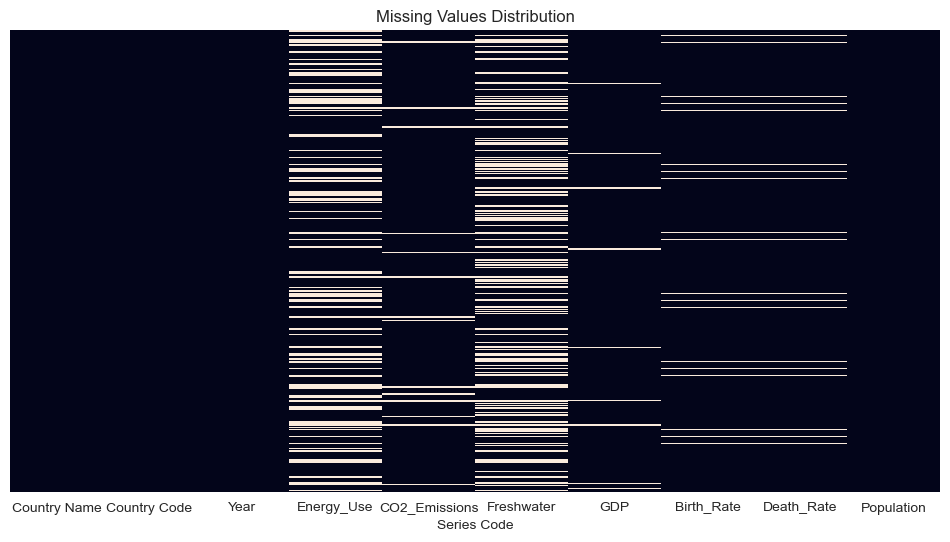

In [18]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Distribution")
plt.show()

### Preparing the CO₂ Target Variable

In [19]:
df = df.dropna(
    subset=["CO2_Emissions"]
)

df = df[
    df["CO2_Emissions"] >= 0
].copy()

print("Dataset after removing missing target valuess:")
print(df.shape)

Dataset after removing missing target valuess:
(6275, 10)


In [20]:
numerical_cols = ["Freshwater","Birth_Rate","CO2_Emissions","Death_Rate","Energy_Use","GDP","Population"]

outlier_summary = {}

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_summary[col] = ((df[col] < lower) |(df[col] > upper)).sum()

display(
    pd.DataFrame(list(outlier_summary.items()),
                 columns=["Feature", "Outlier Count"]
    )
)

,Feature,Outlier Count
0,Freshwater,682
1,Birth_Rate,0
2,CO2_Emissions,1049
3,Death_Rate,179
4,Energy_Use,315
5,GDP,1116
6,Population,1238


## Phase 6 — Exploratory Data Analysis (EDA)

### Objective 1 — Global Average CO₂ Emissions Trend

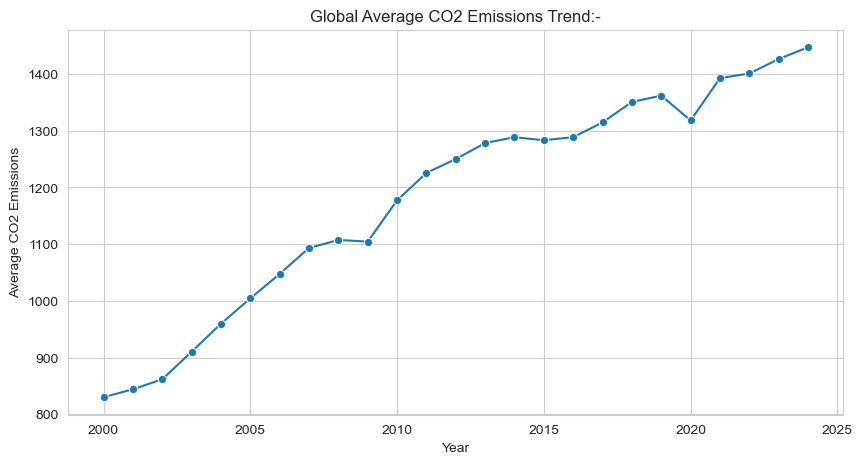

In [21]:
trend = df.groupby("Year")["CO2_Emissions"].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.lineplot(data=trend,x="Year",y="CO2_Emissions",marker="o")

plt.title("Global Average CO2 Emissions Trend:-")
plt.xlabel("Year")
plt.ylabel("Average CO2 Emissions")

plt.show()

### Objective 2 — Identify the Top 10 CO₂ Emitters in the Latest Available Year

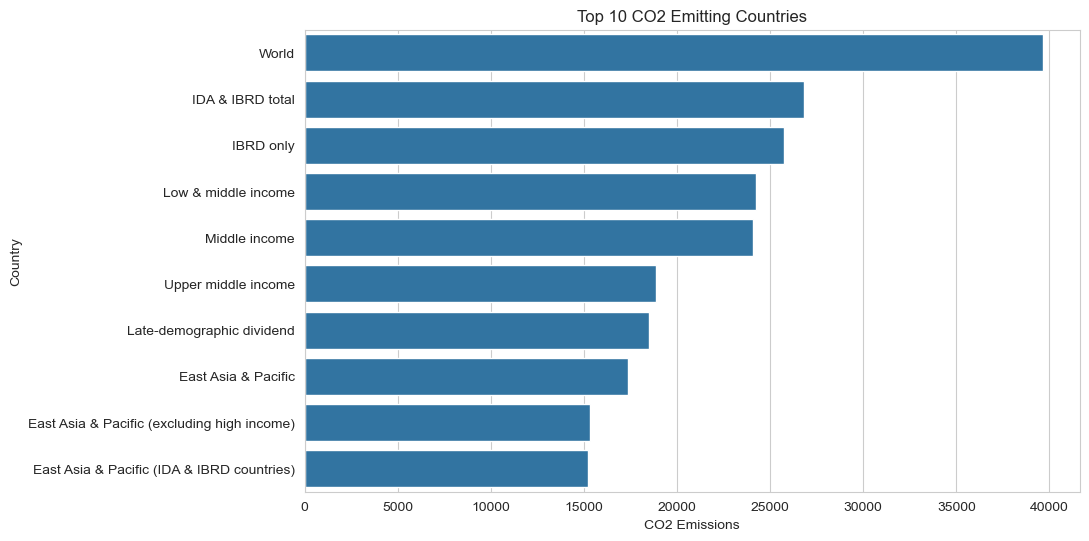

In [22]:
latest = df[df["Year"] == df["Year"].max()]

top_countries = latest.sort_values("CO2_Emissions",ascending=False).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_countries,x="CO2_Emissions",y="Country Name")

plt.title("Top 10 CO2 Emitting Countries")
plt.xlabel("CO2 Emissions")
plt.ylabel("Country")

plt.show()

### Objective 3 — Relationship Between GDP and CO₂ Emissions

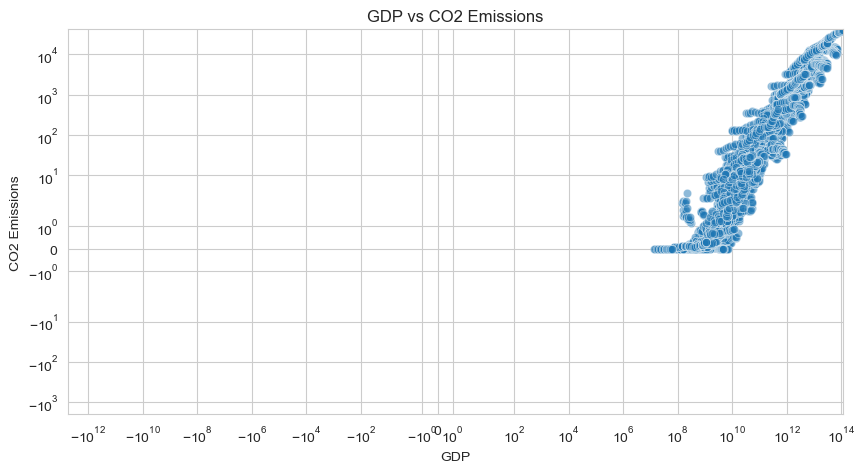

In [23]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="GDP", y="CO2_Emissions", alpha=0.5)

plt.xscale("symlog")
plt.yscale("symlog")

plt.title("GDP vs CO2 Emissions")
plt.xlabel("GDP")
plt.ylabel("CO2 Emissions")

plt.show()

### Objective 4 — Relationship Between Energy Use and CO₂ Emissions

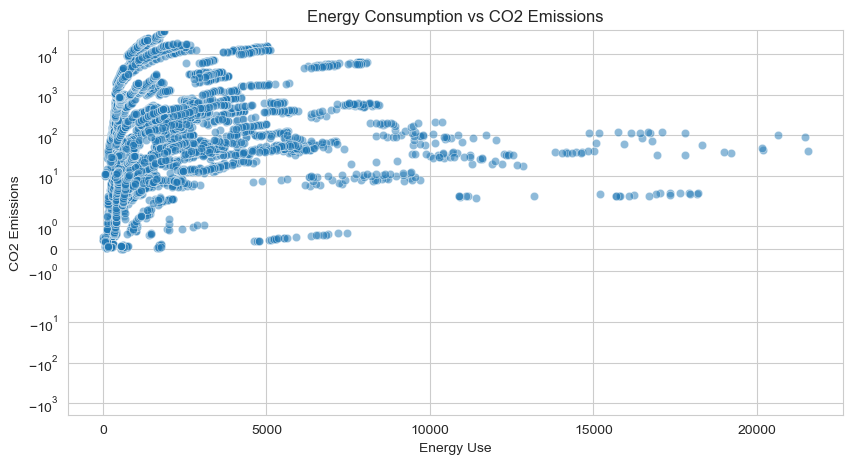

In [24]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df,x="Energy_Use",y="CO2_Emissions",alpha=0.5
)

plt.yscale("symlog")

plt.title("Energy Consumption vs CO2 Emissions")
plt.xlabel("Energy Use")
plt.ylabel("CO2 Emissions")

plt.show()

### Objective 5 — Relationship Between Population and CO₂ Emissions

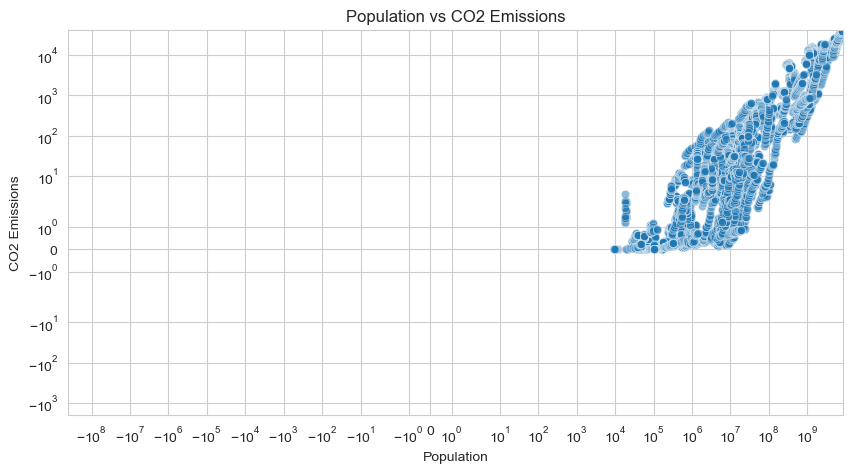

In [25]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="Population", y="CO2_Emissions", alpha=0.5)

plt.xscale("symlog")
plt.yscale("symlog")

plt.title("Population vs CO2 Emissions")
plt.xlabel("Population")
plt.ylabel("CO2 Emissions")

plt.show()

### Objective 6 — Relationship Between Freshwater Withdrawals and CO₂ Emissions

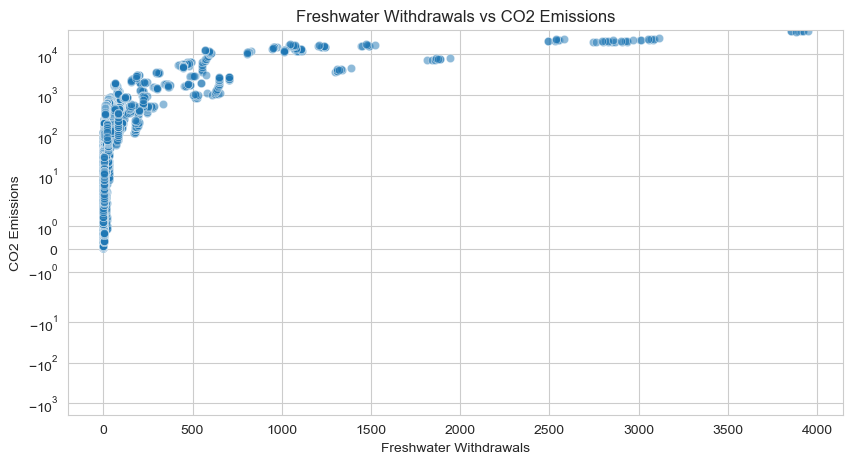

In [26]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="Freshwater", y="CO2_Emissions", alpha=0.5)

plt.yscale("symlog")

plt.title("Freshwater Withdrawals vs CO2 Emissions")
plt.xlabel("Freshwater Withdrawals")
plt.ylabel("CO2 Emissions")

plt.show()

### Objective 7 — Correlation Between Numerical Indicators

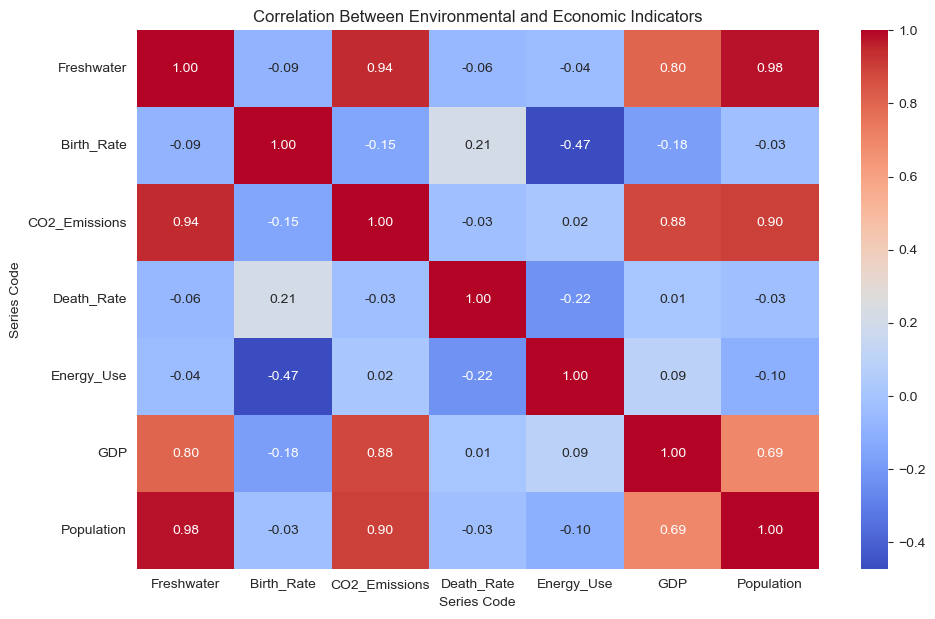

In [27]:
correlation = df[numerical_cols].corr()

plt.figure(figsize=(11, 7))

sns.heatmap(correlation, annot=True,cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Environmental and Economic Indicators")

plt.show()

### Additional EDA — Distribution of CO₂ Emissions Across Years

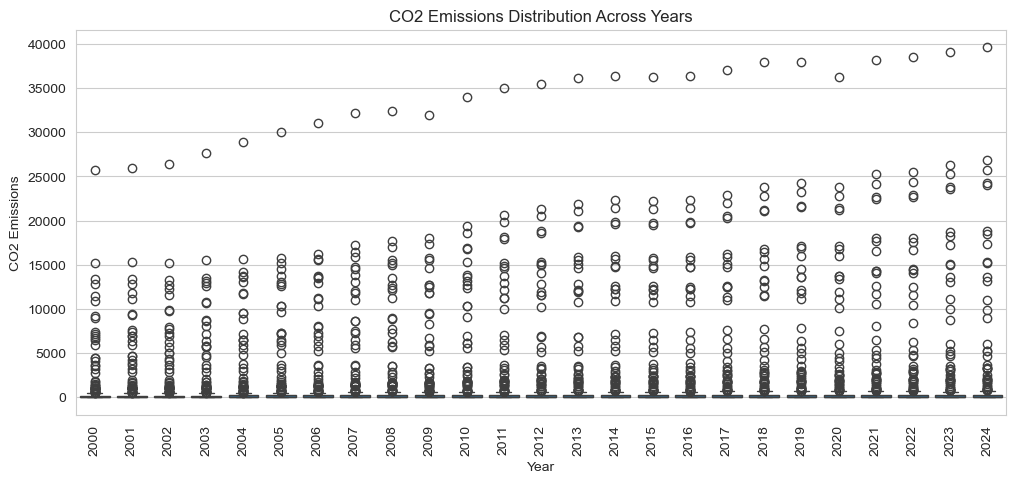

In [28]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df, x="Year", y="CO2_Emissions")

plt.title("CO2 Emissions Distribution Across Years")
plt.xlabel("Year")
plt.ylabel("CO2 Emissions")

plt.xticks(rotation=90)

plt.show()

## Machine-Learning Problem Definition

### Defining the Features and Target

In [29]:
X = df[["GDP",
        "Population",
        "Freshwater",
        "Energy_Use",
        "Birth_Rate",
        "Death_Rate",
        "Year"]]

y = df["CO2_Emissions"]

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (6275, 7)
Dependent Variable Shape: (6275,)


### Splitting the Data into Training and Testing Sets

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training Data: (5020, 7)
Testing Data: (1255, 7)


### Model 1 — Simple Linear Regression

In [31]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(X_train[["GDP"]], y_train)
pred1 = model1.predict(X_test[["GDP"]])

print("Simple Linear Regression R2 Score:", r2_score(y_test, pred1))

Simple Linear Regression R2 Score: 0.7561753561267419


### Model 2 — Multiple Linear Regression

In [32]:
model2 = LinearRegression()
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)

print("Multiple Linear Regression R2 Score:", r2_score(y_test, pred2))

Multiple Linear Regression R2 Score: 0.9270018424587179


### Model 3 — Decision Tree Regressor

A Decision Tree Regressor predicts a numerical value by dividing the feature space into regions using decision rules. It can represent non-linear patterns and interactions, but can be sensitive to the training sample.


In [33]:
model3 = DecisionTreeRegressor(random_state=42)
model3.fit(X_train, y_train)
pred3 = model3.predict(X_test)

print("Decision Tree:")
print("R2 Score:", r2_score(y_test, pred3))

Decision Tree:
R2 Score: 0.9791473687866631


### Model 4 — K-Nearest Neighbors (KNN) Regressor

In [34]:
from sklearn.neighbors import KNeighborsRegressor

model4 = KNeighborsRegressor()

model4.fit(X_train_scaled, y_train)
pred4 = model4.predict(X_test_scaled)

print("KNN Regressor:>")
print("R2 Score:", r2_score(y_test, pred4))

KNN Regressor:>
R2 Score: 0.995476589642694


### Model 5 — Support Vector Regression (SVR)

In [35]:
from sklearn.svm import SVR

model5 = SVR()

model5.fit(X_train_scaled, y_train)

pred5 = model5.predict(X_test_scaled)

print("SVR: ")
print("R2 Score:", r2_score(y_test, pred5))

SVR: 
R2 Score: -0.056844669273695914


In [36]:
predictions = {
    "Simple Linear Regression": pred1,
    "Multiple Linear Regression": pred2,
    "Decision Tree": pred3,
    "KNN": pred4,
    "SVR": pred5
}

## Model Evaluation and Comparison
**R² score (coefficient of determination):

**Mean Absolute Error (MAE):

**Root Mean Squared Error (RMSE)

In [37]:
results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred))})

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "RMSE",
        ascending=True
    ).reset_index(drop=True))

,Model,R2 Score,MAE,RMSE
0,KNN,0.995477,87.686496,237.875603
1,Decision Tree,0.979147,76.829579,510.737021
2,Multiple Linear Regression,0.927002,433.423955,955.592775
3,Simple Linear Regression,0.756175,664.456232,1746.448193
4,SVR,-0.056845,1009.298086,3635.988396


### Comparing R² Scores

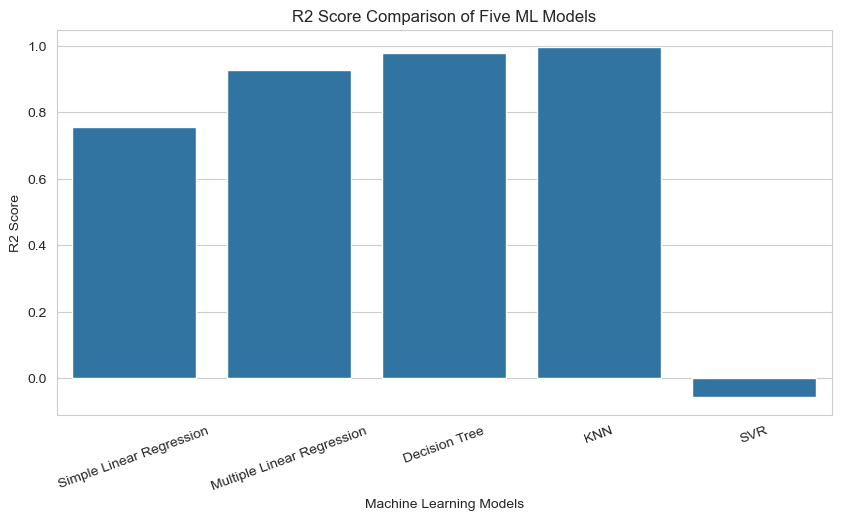

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results_df,x="Model",y="R2 Score")

plt.title("R2 Score Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

### Comparing MAE and RMSE

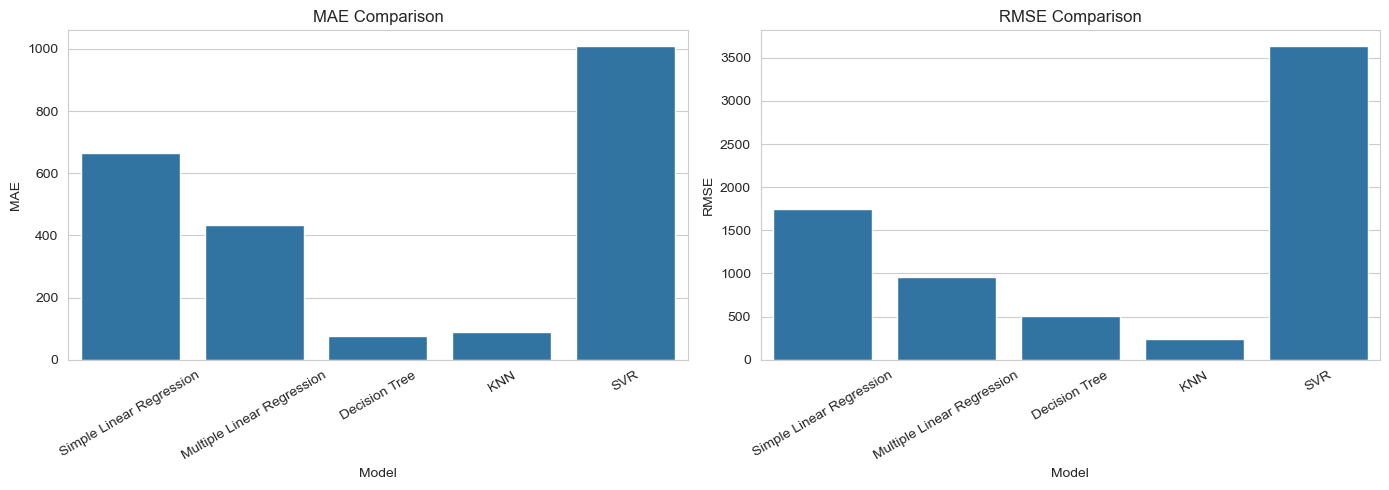

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])

axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Selecting the Best Model Based on RMSE

In [40]:
best_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("BEST PERFORMING Model:->")

print("Model:", best_model["Model"])
print("R2 Score:", best_model["R2 Score"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])

BEST PERFORMING Model:->
Model: KNN
R2 Score: 0.995476589642694
MAE: 87.68649624063747
RMSE: 237.87560291770023


## Prediction Visualization

### Actual vs. Predicted CO₂ Emissions

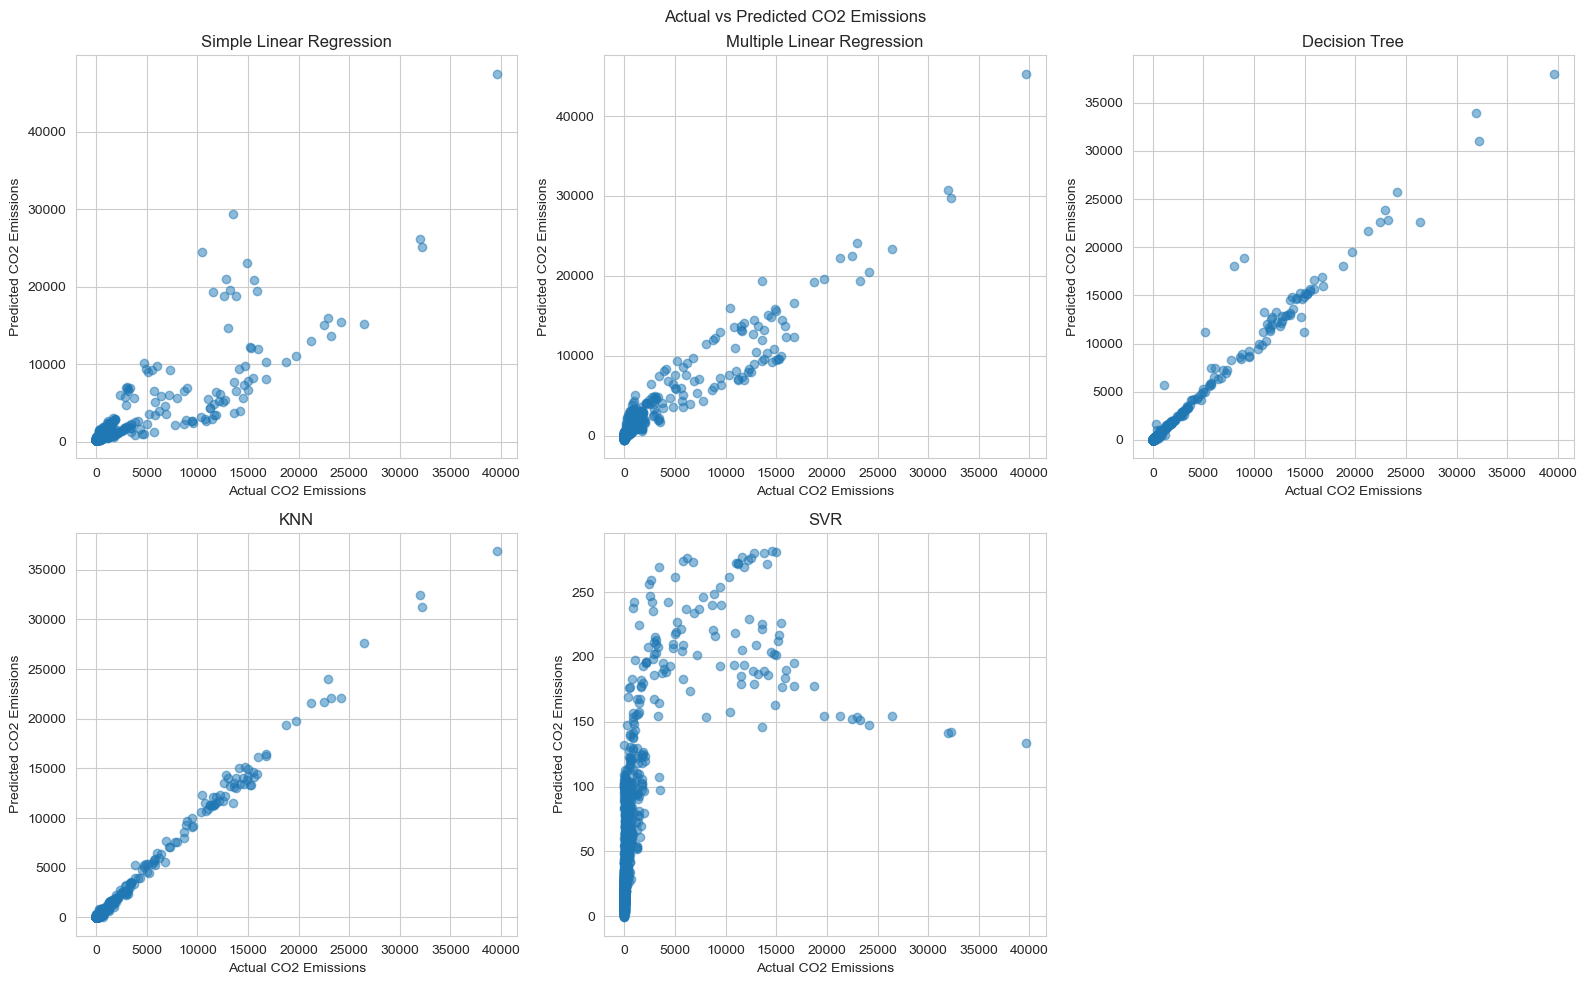

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, pred) in enumerate(predictions.items()):
    axes[i].scatter(y_test, pred, alpha=0.5)

    axes[i].set_title(name)
    axes[i].set_xlabel("Actual CO2 Emissions")
    axes[i].set_ylabel("Predicted CO2 Emissions")

axes[-1].axis("off")
plt.suptitle("Actual vs Predicted CO2 Emissions")
plt.tight_layout()
plt.show()

### Multiple Linear Regression Coefficients

In [42]:
coefficients = pd.DataFrame({"Feature": X_train.columns,
    "Coefficient": model2.coef_})
display(coefficients)

,Feature,Coefficient
0,GDP,2.295554e-10
1,Population,2.437718e-06
2,Freshwater,1.175108e-01
3,Energy_Use,2.982200e-02
4,Birth_Rate,-1.291274e+01
5,Death_Rate,-7.793990e-01
6,Year,3.733349e+00


## Final Results and Conclusion

In [43]:
print("FINAL MACHINE LEARNING RESULTS:->")

print("\nTotal Models Implementation:", len(predictions))
print("\nBest Performing Model:", best_model["Model"])
print("\nR2 Score:", round(best_model["R2 Score"], 4))
print("MAE:", round(best_model["MAE"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("\nMODEL RANKING")
display(results_df.sort_values("RMSE").reset_index(drop=True))
print("\nMULTIPLE LINEAR REGRESSION COEFFICIENTS")
display(coefficients)


FINAL MACHINE LEARNING RESULTS:->

Total Models Implementation: 5

Best Performing Model: KNN

R2 Score: 0.9955
MAE: 87.6865
RMSE: 237.8756

MODEL RANKING


,Model,R2 Score,MAE,RMSE
0,KNN,0.995477,87.686496,237.875603
1,Decision Tree,0.979147,76.829579,510.737021
2,Multiple Linear Regression,0.927002,433.423955,955.592775
3,Simple Linear Regression,0.756175,664.456232,1746.448193
4,SVR,-0.056845,1009.298086,3635.988396



MULTIPLE LINEAR REGRESSION COEFFICIENTS


,Feature,Coefficient
0,GDP,2.295554e-10
1,Population,2.437718e-06
2,Freshwater,1.175108e-01
3,Energy_Use,2.982200e-02
4,Birth_Rate,-1.291274e+01
5,Death_Rate,-7.793990e-01
6,Year,3.733349e+00


,Feature,Importance
0,GDP,0.743156
1,Population,0.237162
3,Energy_Use,0.008915
4,Birth_Rate,0.005626
5,Death_Rate,0.003062
6,Year,0.001164
2,Freshwater,0.000915


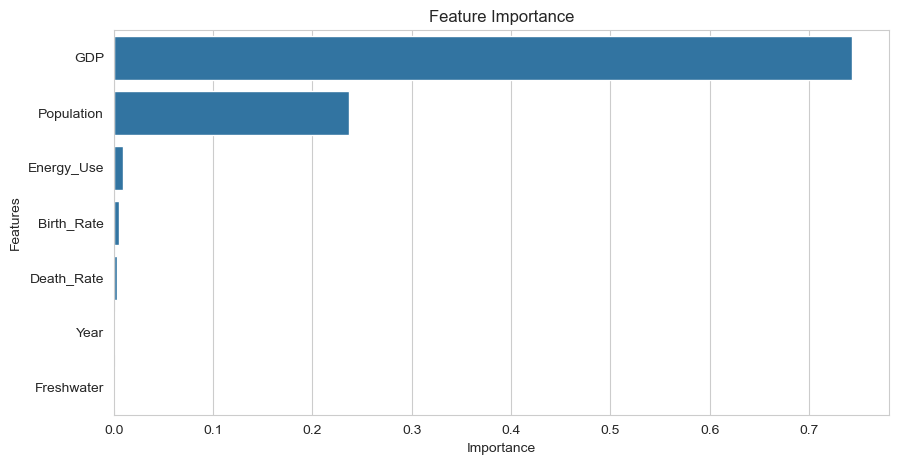

In [44]:
importance = pd.DataFrame({"Feature": X_train.columns,
    "Importance": model3.feature_importances_})

importance = importance.sort_values("Importance", ascending=False)
display(importance)

plt.figure(figsize=(10, 5))

sns.barplot(data=importance, x="Importance", y="Feature")

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()